## Modelo ideal
Utilizaré QuTiP para resolver la ecuación de Schrödinger dependiente del tiempo.

Definimos el Hamiltoniano utilizando matrices de Pauli:

$$ \hat{H} = \hat{H}_0 + \hat{H}_1(t) $$

Asumimos $\hbar = 1$ para que la simulacion salga facilita, el Hamiltoniano lo definimos usando la matriz de Pauli $\sigma_z$:

$$ \hat{H}_0 = -\frac{\omega_0}{2} \hat{\sigma}_z $$

Donde $\omega_0$ representa la frecuencia de transición natural de nuestro sistema cuántico de dos niveles.

La interacción con el campo oscilante transversal (que en nuestro caso representará los pulsos de radiofrecuencia sobre los espines nucleares) se modela mediante la matriz de Pauli $\sigma_x$:

$$ \hat{H}_1(t) = \Omega \cos(\omega t) \hat{\sigma}_x $$

Acá $\Omega$ corresponde a la frecuencia de Rabi, que es proporcional a la amplitud del campo aplicado, y $\omega$ es la frecuencia de oscilación de dicho campo.

Ahora, para empezar hay que instalar QuTiP y luego importar y hacer las cosas bonitas del documento:

In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 60.4 MB/s  0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import *

# estado inicial del qubit
# basis(2, 0) representa el estado fundamental |0> (spin hacia arriba)
estado_inicial = basis(2, 0)

# operadores (Matrices de Pauli)
# QuTiP ya tiene estas matrices listas para usar
sz = sigmaz()
sx = sigmax()

# Imprimimos el estado inicial para verificar que se creó correctamente
estado_inicial

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[1.]
 [0.]]

### Construcción del Hamiltoniano en Resonancia

Para la simulación en resonancia trabajamos con valores adimensionales.
Configuré la frecuencia del campo de control para que sea igual a la frecuencia natural del qubit, definiendo la condición de resonancia.

En QuTiP, los Hamiltonianos dependientes del tiempo se construyen estructurando $\hat{H} = \hat{H}_0 + \hat{H}_1(t)$ en una lista: `[H0, [H1, funcion_temporal]]`.

In [ ]:
# Definición de parámetros base adimensionales
omega_0 = 1.0  # Frecuencia de transición
omega = 1.0    # Frecuencia del pulso de radiofrecuencia o resonancia
Omega = 0.1    # Frecuencia de Rabi (amplitud)

# Construcción de la parte estática del Hamiltoniano
H0 = -0.5 * omega_0 * sz

# Construcción de la parte que interactúa
H1 = sx

# Función que describe cómo cambia el campo en el tiempo
def dependencia_temporal(t, args):
    return args['Omega'] * np.cos(args['omega'] * t)

# Hamiltoniano total en formato QuTiP
H_total = [H0, [H1, dependencia_temporal]]
argumentos = {'Omega': Omega, 'omega': omega}

# mensaje de confirmación
print("Hamiltoniano construido")

Hamiltoniano construido


### Ecuación de Schrödinger

Par aver la dinámica del sistema utilicé la función `mesolve` de QuTiP, esta integra la ecuación de Schrödinger a lo largo de un vector de tiempo continuo.

Para graficar la probabilidad de ocupación del estado excitado $|1\rangle$, definimos el operador de proyección $\hat{P}_1 = |1\rangle\langle1|$. Al pasar este operador a `mesolve`, la función calculará automáticamente el valor esperado $\langle \hat{P}_1 \rangle(t)$, que corresponde exactamente a la probabilidad de encontrar el qubit en el estado $|1\rangle$ en cada instante de tiempo.

/usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


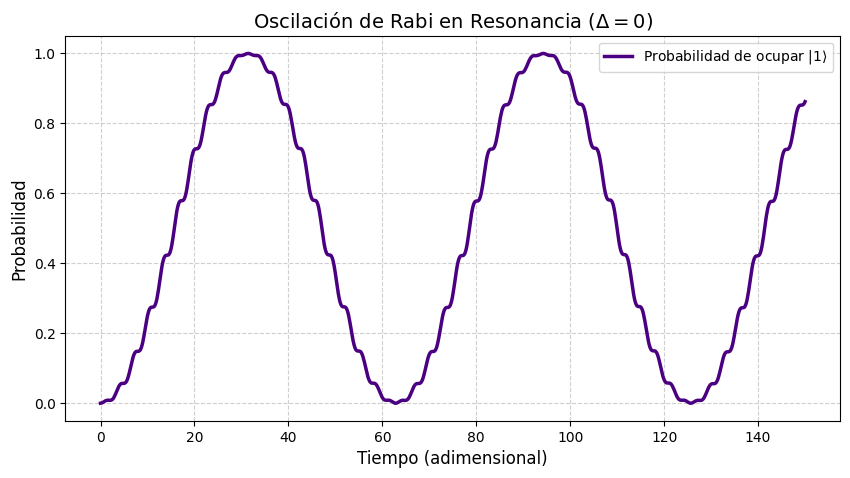

In [ ]:
# proyector para el estado excitado |1>
from qutip import *
# proyector para el estado excitado |1>
proyector_1 = basis(2, 1) * basis(2, 1).dag()

# arreglo de tiempo para la simulación
# Como Omega = 0.1, un periodo completo de oscilación es T = 2*pi/0.1 ≈ 62.8
# Simularemos hasta t=150 para ver más de dos ciclos completos
tlist = np.linspace(0, 150, 1000)

# Ejecutamos
# Argumentos de mesolve: (Hamiltoniano, estado inicial, tiempo, [operadores_colapso], [operadores_medición], argumentos)
resultado_resonancia = mesolve(H_total, estado_inicial, tlist, e_ops=[proyector_1], args=argumentos)

# Extraemos las probabilidades
probabilidades_1 = resultado_resonancia.expect[0]

# Graficamos
plt.figure(figsize=(10, 5))
plt.plot(tlist, probabilidades_1, label='Probabilidad de ocupar $|1\\rangle$', color='indigo', linewidth=2.5)

plt.title(r'Oscilación de Rabi en Resonancia ($\Delta = 0$)', fontsize=14)
plt.xlabel('Tiempo (adimensional)', fontsize=12)
plt.ylabel('Probabilidad', fontsize=12)

plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.show()

### Simulación Fuera de Resonancia (Desentonamiento)

En un escenario real, es común que la frecuencia del pulso de control ($\omega$) no coincida exactamente con la frecuencia de transición del qubit ($\omega_0$). A esta diferencia se le llama desentonamiento (detuning): $\Delta = \omega_0 - \omega$.

Para observar este efecto, modificaremos la frecuencia de nuestro campo de control de $\omega = 1.0$ a $\omega = 0.9$ (un desentonamiento de $\Delta = 0.1$) manteniendo la misma amplitud, y superpondremos los resultados con el caso resonante.

<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2217/2463953414.py:12: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(tlist, probabilidades_1, label='Resonancia ($\Delta = 0$)', color='indigo', linewidth=2, alpha=0.4)


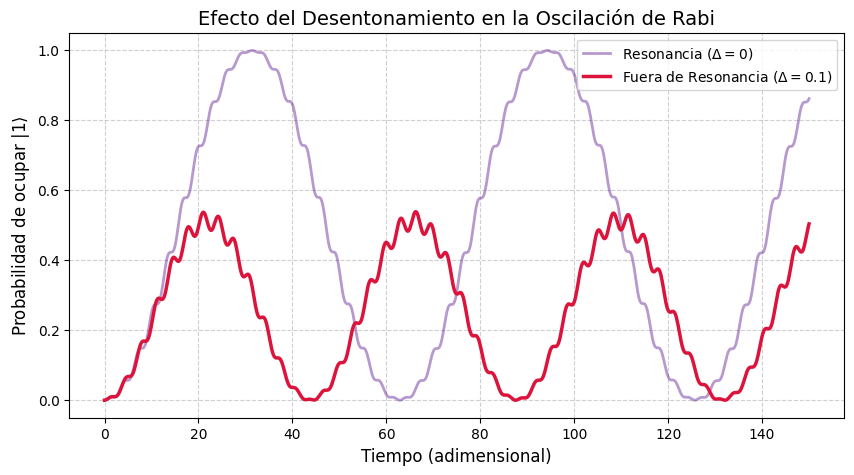

In [ ]:
# Definimos la nueva frecuencia desentonada
omega_desentonado = 0.9
argumentos_desentonado = {'Omega': Omega, 'omega': omega_desentonado}

# Ejecutamos con el nuevo argumento
resultado_desentonado = mesolve(H_total, estado_inicial, tlist, e_ops=[proyector_1], args=argumentos_desentonado)
probabilidades_desentonadas = resultado_desentonado.expect[0]

# Graficamos ambos casos
plt.figure(figsize=(10, 5))
plt.plot(tlist, probabilidades_1, label='Resonancia ($\Delta = 0$)', color='indigo', linewidth=2, alpha=0.4)
plt.plot(tlist, probabilidades_desentonadas, label=r'Fuera de Resonancia ($\Delta = 0.1$)', color='crimson', linewidth=2.5)

plt.title('Efecto del Desentonamiento en la Oscilación de Rabi', fontsize=14)
plt.xlabel('Tiempo (adimensional)', fontsize=12)
plt.ylabel('Probabilidad de ocupar $|1\\rangle$', fontsize=12)

plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.show()

### Un pequeño análisis de la simulación de arriba
Acá pueden ver que las curvas se ven como rugosas y no completamente lisas, esto se debe a que arriba se está procesando el Hamiltoniano exacto y conservando los términos contra-rotatorios los cuales normalmente desaparecen cuando se asume la Aproximación de Onda Rotatoria (RWA) en los cálculos analíticos.

### Comparación con la Aproximación de Onda Rotatoria (RWA)

Acá va una comparación con la aproximación de RWA junto a una pequeña explicación:

Al pasar a un marco de referencia que rota a la frecuencia del campo de control, los términos que oscilan rápidamente (a frecuencia $\approx 2\omega$) se promedian a cero. El Hamiltoniano resultante se vuelve independiente del tiempo:

$$ \hat{H}_{RWA} = -\frac{\Delta}{2} \hat{\sigma}_z + \frac{\Omega}{2} \hat{\sigma}_x $$

Donde $\Delta = \omega_0 - \omega$ es el desentonamiento.

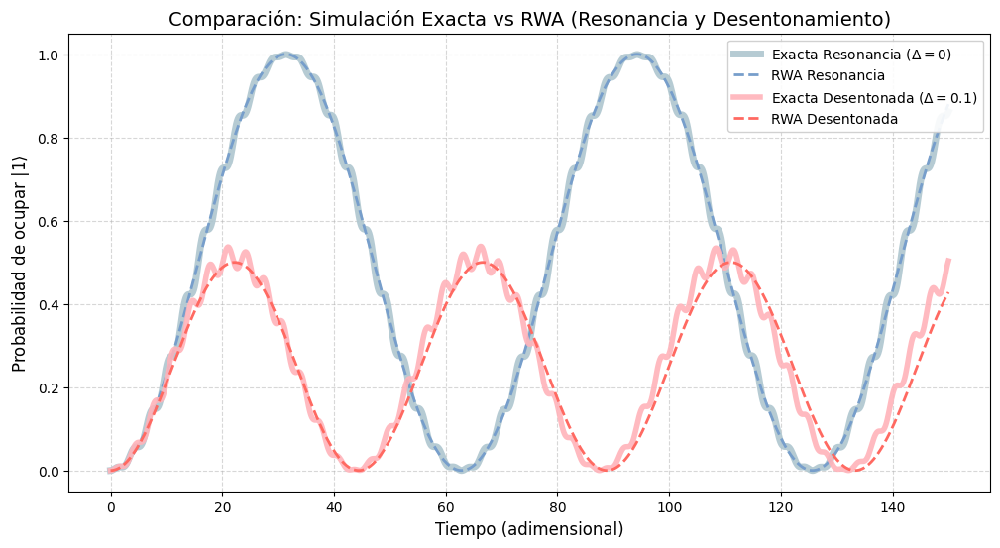

In [ ]:
# aproximación RWA para el caso en resonancia (Delta = 0)
H_RWA_resonancia = 0.5 * Omega * sx
resultado_RWA_resonancia = mesolve(H_RWA_resonancia, estado_inicial, tlist, e_ops=[proyector_1])
probabilidades_RWA_resonancia = resultado_RWA_resonancia.expect[0]

plt.figure(figsize=(12, 6))

# --- Resonancia  ---
plt.plot(tlist, probabilidades_1, label=r'Exacta Resonancia ($\Delta = 0$)', color='#AEC6CF', linewidth=5.0, alpha=0.9)
plt.plot(tlist, probabilidades_RWA_resonancia, label=r'RWA Resonancia', color='#779ECB', linestyle='--', linewidth=2.0)

# --- Desentonado ---
plt.plot(tlist, probabilidades_desentonadas, label=r'Exacta Desentonada ($\Delta = 0.1$)', color='#FFB3BA', linewidth=4.0, alpha=0.9)
plt.plot(tlist, probabilidades_RWA, label=r'RWA Desentonada', color='#FF6961', linestyle='--', linewidth=2.0)

# Configuraciones visuales
plt.title('Comparación: Simulación Exacta vs RWA (Resonancia y Desentonamiento)', fontsize=14)
plt.xlabel('Tiempo (adimensional)', fontsize=12)
plt.ylabel(r'Probabilidad de ocupar $|1\rangle$', fontsize=12)

plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(loc='upper right', framealpha=0.9, fontsize=10)

plt.show()

Acá hay algo muy interesante, la onda roja se desfasa levemente al final, esto se debe al Corrimiento de Bloch-Siegert (Bloch-Siegert shift)

La aproximación RWA asume que las vibraciones muy rápidas (términos contra-rotatorios) no tienen efecto neto. Sin embargo, en la realidad, estos términos modifican ligeramente los niveles de energía del qubit, alterando su verdadera frecuencia de oscilación. Aunque la diferencia es pequeña, el error se acumula con el tiempo, haciendo que las ondas se desfasen visualmente.

### Trayectoria en la Esfera de Bloch
Acá hice la comparación de qutip y de matplotlib, ahí vemos cuál se ve más bomnita

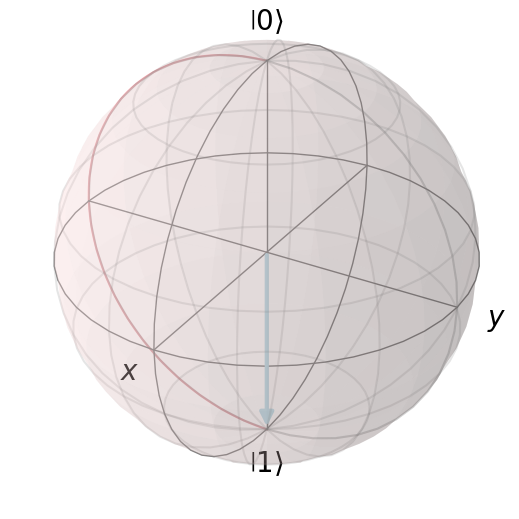

In [ ]:
# esta está hecha con qutip, la verdad no me gustó mucho lol
tiempo_pi = np.pi / Omega
tlist_bloch = np.linspace(0, tiempo_pi, 100)

resultado_bloch = mesolve(H_RWA_resonancia, estado_inicial, tlist_bloch)
estados = resultado_bloch.states

sy = sigmay()

coord_x = expect(sx, estados)
coord_y = expect(sy, estados)
coord_z = expect(sz, estados)

# Qutip tiene un comando directo para simular una esfera de bloch :D
esfera = Bloch()

esfera.point_color = ['#FFB3BA']
esfera.point_marker = ['o']

esfera.add_points([coord_x, coord_y, coord_z], meth='l')

esfera.vector_color = ['#AEC6CF']
esfera.add_states(estados[-1])

esfera.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import mpl_toolkits.mplot3d.axes3d as p3

# las coordenadas de la segunda trayectoria (fuera de resonancia)
resultado_bloch_desentonado = mesolve(H_RWA, estado_inicial, tlist_bloch)
estados_desentonados = resultado_bloch_desentonado.states

coord_x_des = expect(sx, estados_desentonados)
coord_y_des = expect(sy, estados_desentonados)
coord_z_des = expect(sz, estados_desentonados)

# Configuramos la figura
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.set_box_aspect([1, 1, 1])

ax.set_facecolor('none')
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

# Dibujamos la esfera base y los ejes
u = np.linspace(0, 2 * np.pi, 60)
v = np.linspace(0, np.pi, 60)
x = np.outer(np.cos(u), np.sin(v))
y = np.outer(np.sin(u), np.sin(v))
z = np.outer(np.ones(np.size(u)), np.cos(v))

ax.plot_wireframe(x, y, z, color='gray', alpha=0.15, linewidth=0.5)
ax.plot([-1.2, 1.2], [0, 0], [0, 0], color='black', alpha=0.3, linewidth=1)
ax.plot([0, 0], [-1.2, 1.2], [0, 0], color='black', alpha=0.3, linewidth=1)
ax.plot([0, 0], [0, 0], [-1.2, 1.2], color='black', alpha=0.3, linewidth=1)

ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.set_zlabel('z', fontsize=12)
ax.set_xlim([-1.1, 1.1])
ax.set_ylim([-1.1, 1.1])
ax.set_zlim([-1.1, 1.1])
ax.set_title('Trayectorias de Bloch: Resonancia vs Desentonamiento', fontsize=14)

# elev = inclinación (arriba/abajo), azim = rotación (izquierda/derecha)
ax.view_init(elev=20, azim=60)

# Preparamos las trayectorias para animar
# Resonancia
linea_res, = ax.plot([], [], [], color='#AEC6CF', linewidth=3, label=r'Resonancia ($\Delta=0$)')
punto_res, = ax.plot([], [], [], marker='o', color='#779ECB', markersize=8)

# Desentonado
linea_des, = ax.plot([], [], [], color='#FFB3BA', linewidth=2, linestyle='--', label=r'Desentonado ($\Delta=0.1$)')
punto_des, = ax.plot([], [], [], marker='o', color='#FF6961', markersize=6)

ax.legend(loc='upper right')

# Funciones de animación para dos líneas
def inicializar():
    linea_res.set_data([], [])
    linea_res.set_3d_properties([])
    punto_res.set_data([], [])
    punto_res.set_3d_properties([])

    linea_des.set_data([], [])
    linea_des.set_3d_properties([])
    punto_des.set_data([], [])
    punto_des.set_3d_properties([])
    return linea_res, punto_res, linea_des, punto_des

def animar(i):
    # Animación línea resonante
    linea_res.set_data(coord_x[:i], coord_y[:i])
    linea_res.set_3d_properties(coord_z[:i])
    punto_res.set_data([coord_x[i]], [coord_y[i]])
    punto_res.set_3d_properties([coord_z[i]])

    # Animación línea desentonada
    linea_des.set_data(coord_x_des[:i], coord_y_des[:i])
    linea_des.set_3d_properties(coord_z_des[:i])
    punto_des.set_data([coord_x_des[i]], [coord_y_des[i]])
    punto_des.set_3d_properties([coord_z_des[i]])

    return linea_res, punto_res, linea_des, punto_des

# animación interactiva
animacion = FuncAnimation(fig, animar, frames=len(coord_x)-1,
                          init_func=inicializar, blit=False, interval=40)

plt.close(fig)
HTML(animacion.to_jshtml())